<a href="https://colab.research.google.com/github/akshat280706/IP-LABS/blob/main/IP_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip -q install PyWavelets opencv-python-headless scikit-image

In [ ]:
import os
import cv2
import numpy as np
import pandas as pd
import pywt
import matplotlib.pyplot as plt
from google.colab import files
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

upload the cover img:


Saving scenery.jpeg to scenery.jpeg
Cover image loaded: scenery.jpeg

upload watermark img:


Saving watermark.jpeg to watermark.jpeg
watermark loaded: watermark.jpeg

Embedding watermark...
Extracting watermark from saved PNG...


IMAGE QUALITY METRICS
PSNR                 : 49.9360 dB
SSIM                 : 0.997918


WATERMARK RECOVERY METRICS
Total watermark bits : 1024
Incorrect bits       : 0
BER                  : 0.000000
Recovery Accuracy    : 100.00%
Normalized Correlation: 1.000000


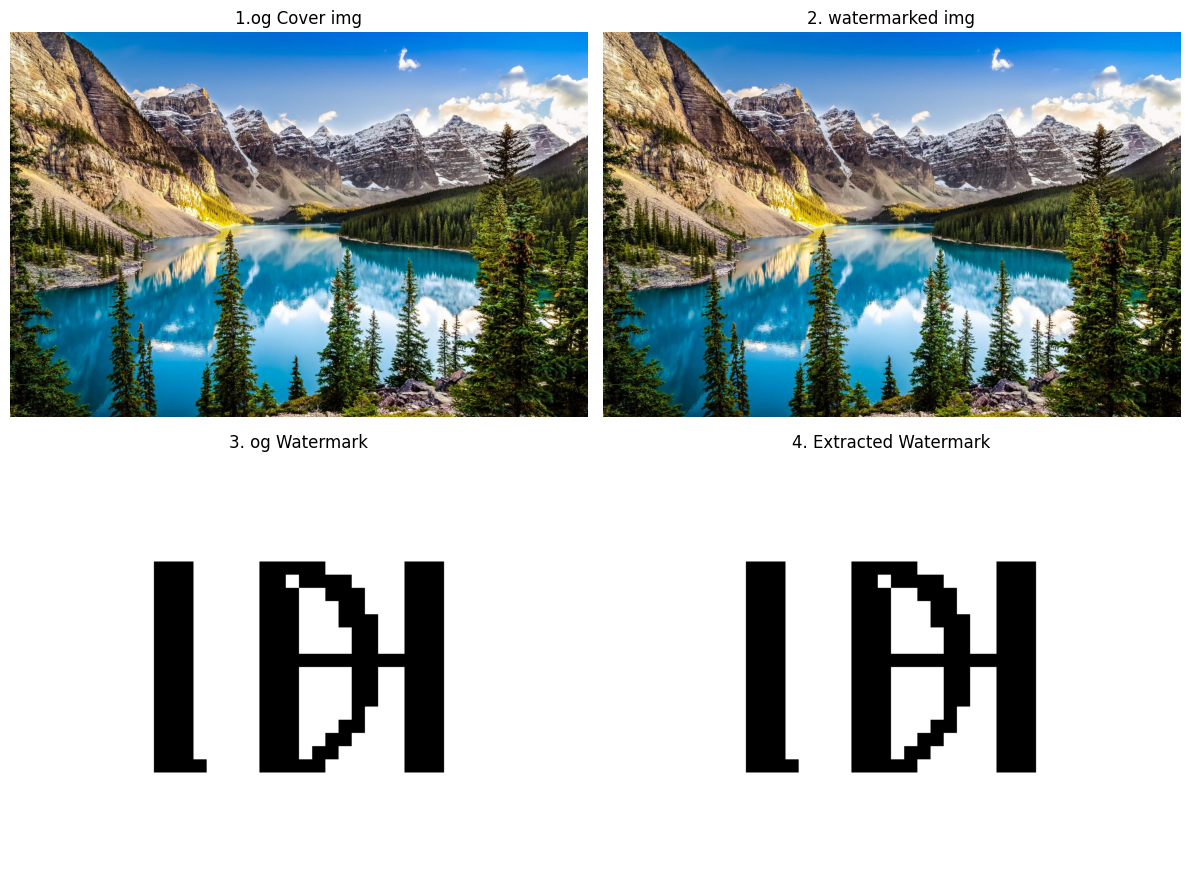


Output files saved in: watermark_output

Watermarked image: watermark_output/watermarked.png
Extracted watermark: watermark_output/extracted_watermark.png


In [ ]:
#cover img upload

print("upload the cover img:")
cover_upload = files.upload()
if len(cover_upload)!=1:
    raise ValueError("upload only one img.")

cover_name=next(iter(cover_upload.keys()))
cover_array=np.frombuffer(cover_upload[cover_name],np.uint8)
cover=cv2.imdecode(cover_array,cv2.IMREAD_COLOR)

if cover is None:
    raise ValueError("wrong img")
print("Cover image loaded:",cover_name)


#watermark img upload
print("\nupload watermark img:")
logo_upload = files.upload()

if len(logo_upload)!=1:
    raise ValueError("upload only one watermark img.")

logo_name=next(iter(logo_upload.keys()))
logo_array=np.frombuffer(logo_upload[logo_name],np.uint8)
logo_gray=cv2.imdecode(logo_array,cv2.IMREAD_GRAYSCALE)

if logo_gray is None:
    raise ValueError("invalid watermark img")
print("watermark loaded:", logo_name)


OUTPUT_DIR = "watermark_output"
STRENGTH = 12.0
WM_WIDTH = 32
WM_HEIGHT = 32
os.makedirs(OUTPUT_DIR, exist_ok=True)

#watermark img to binary
def read_binary_watermark(image_gray, size):
    resized=cv2.resize(image_gray,size,interpolation=cv2.INTER_AREA)
    _,binary=cv2.threshold(resized,0,1,cv2.THRESH_BINARY+cv2.THRESH_OTSU)
    return binary.astype(np.uint8)


#DCT and inverse DCT
def dct2(block):
    return cv2.dct(np.float32(block))


def idct2(coefficients):
    return cv2.idct(np.float32(coefficients))



#watermark using DWT and DCT
def embed_watermark(cover_image,watermark,alpha=12.0):

    #BGR to YCrCb
    ycrcb=cv2.cvtColor(cover_image,cv2.COLOR_BGR2YCrCb)
    y=ycrcb[:,:,0].astype(np.float32)

    #DWT
    LL,(LH,HL,HH)=pywt.dwt2(y,"haar")

    block_size=8
    rows=HL.shape[0]//block_size
    cols=HL.shape[1]//block_size

    if watermark.size>rows*cols:
        raise ValueError(
            f"Watermark needs {watermark.size} bits, "
            f"but image supports only {rows * cols} bits. "
            "Use a larger cover image."
        )

    coeff_a=(2,3)
    coeff_b=(3,2)

    output_hl=HL.copy()

    #embed each watermark bit
    for i,bit in enumerate(watermark.flatten()):

        r=(i//cols)*block_size
        c=(i%cols)*block_size

        block=output_hl[r:r+block_size,c:c+block_size]
        coeff=dct2(block)
        a=coeff[coeff_a]
        b=coeff[coeff_b]
        difference=a-b

        if bit==1 and difference<alpha:
            midpoint=(a+b)/2.0

            coeff[coeff_a]=midpoint+alpha/2.0
            coeff[coeff_b]=midpoint-alpha/2.0

        elif bit==0 and difference>-alpha:

            midpoint=(a+b)/2.0

            coeff[coeff_a]=midpoint-alpha/2.0
            coeff[coeff_b]=midpoint+alpha/2.0

        output_hl[r:r+block_size,c:c+block_size]=idct2(coeff)

    #inverse DWT
    reconstructed_y=pywt.idwt2((LL,(LH,output_hl, HH)),"haar")
    reconstructed_y=reconstructed_y[:y.shape[0],:y.shape[1]]

    ycrcb[:,:,0]=np.clip(reconstructed_y,0,255).astype(np.uint8)
    watermarked_image=cv2.cvtColor(ycrcb,cv2.COLOR_YCrCb2BGR)
    return watermarked_image


#extracting watermark
def extract_watermark(watermarked_image, watermark_shape):
    ycrcb=cv2.cvtColor(watermarked_image,cv2.COLOR_BGR2YCrCb)

    y=ycrcb[:,:,0].astype(np.float32)

    #DWT
    _,(_,HL,_)=pywt.dwt2(y,"haar")

    block_size=8

    rows=HL.shape[0]//block_size
    cols=HL.shape[1]//block_size

    total_bits=int(np.prod(watermark_shape))

    if total_bits>rows*cols:
        raise ValueError("Watermark exceeds extraction capacity.")

    coeff_a=(2,3)
    coeff_b=(3,2)
    bits=[]

    for i in range(total_bits):

        r=(i//cols)*block_size
        c=(i%cols)*block_size

        block=HL[r:r+block_size,c:c+block_size]
        coeff=dct2(block)

        difference=(coeff[coeff_a]-coeff[coeff_b])
        bits.append(1 if difference > 0 else 0)

    extracted=np.array(bits, dtype=np.uint8).reshape(watermark_shape)
    return extracted



#img quality matrix
def calculate_image_quality(original, watermarked):
    psnr=peak_signal_noise_ratio(original,watermarked,data_range=255)
    ssim=structural_similarity(original,watermarked,channel_axis=2,data_range=255)
    return psnr, ssim


#watermark recovery matrix
def calculate_recovery_metrics(original_wm, extracted_wm):

    original = original_wm.flatten().astype(np.float64)
    extracted = extracted_wm.flatten().astype(np.float64)

    # Bit Error Rate
    incorrect_bits=np.count_nonzero(original!=extracted)
    total_bits=original.size
    ber=incorrect_bits/total_bits

    # Recovery Accuracy
    accuracy=(1-ber)*100

    # Normalized Correlation (cosine similarity)
    denominator=(np.linalg.norm(original)*np.linalg.norm(extracted))

    if denominator==0:
        nc=1.0 if np.array_equal(original,extracted) else 0.0
    else:
        nc=np.dot(original,extracted)/denominator

    return ber,accuracy,nc,incorrect_bits,total_bits

#watermark
watermark=read_binary_watermark(logo_gray,(WM_WIDTH,WM_HEIGHT))

print("\nEmbedding watermark...")
watermarked=embed_watermark(cover,watermark,alpha=STRENGTH)

#save img
watermarked_path=os.path.join(OUTPUT_DIR,"watermarked.png")

if not cv2.imwrite(watermarked_path, watermarked):
    raise RuntimeError("Failed to save watermarked image.")

saved_watermarked=cv2.imread(watermarked_path,cv2.IMREAD_COLOR)

if saved_watermarked is None:
    raise RuntimeError("Failed to reload watermarked image.")
print("Extracting watermark from saved PNG...")

extracted=extract_watermark(saved_watermarked,watermark.shape)

extracted_path=os.path.join(OUTPUT_DIR,"extracted_watermark.png")

if not cv2.imwrite(extracted_path, extracted*255):
    raise RuntimeError("Failed to save extracted watermark.")


#matrix calculation
psnr,ssim=calculate_image_quality(cover,saved_watermarked)

ber,accuracy,nc,incorrect_bits,total_bits=(calculate_recovery_metrics(watermark,extracted))

print("\n")
print("IMAGE QUALITY METRICS")

print(f"PSNR                 : {psnr:.4f} dB")
print(f"SSIM                 : {ssim:.6f}")

print("\n")
print("WATERMARK RECOVERY METRICS")

print(f"Total watermark bits : {total_bits}")
print(f"Incorrect bits       : {incorrect_bits}")
print(f"BER                  : {ber:.6f}")
print(f"Recovery Accuracy    : {accuracy:.2f}%")
print(f"Normalized Correlation: {nc:.6f}")


#result display
cover_rgb=cv2.cvtColor(cover,cv2.COLOR_BGR2RGB)

watermarked_rgb=cv2.cvtColor(saved_watermarked,cv2.COLOR_BGR2RGB)

original_logo_display=cv2.resize(watermark*255,(256,256),interpolation=cv2.INTER_NEAREST)
extracted_logo_display=cv2.resize(extracted*255,(256,256),interpolation=cv2.INTER_NEAREST)

plt.figure(figsize=(12,9))

plt.subplot(2, 2, 1)
plt.imshow(cover_rgb)
plt.title("1.og Cover img")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(watermarked_rgb)
plt.title("2. watermarked img")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(original_logo_display,cmap="gray",vmin=0,vmax=255)
plt.title("3. og Watermark")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(extracted_logo_display,cmap="gray",vmin=0,vmax=255)
plt.title("4. Extracted Watermark")
plt.axis("off")

plt.tight_layout()
plt.show()


#results download
print("\nOutput files saved in:", OUTPUT_DIR)
print("\nWatermarked image:", watermarked_path)
print("Extracted watermark:", extracted_path)

# Uncomment to download:
# files.download(watermarked_path)
# files.download(extracted_path)

In [ ]:
  !zip -j figs.zip scenery.jpeg watermark.jpeg watermark_output/watermarked.png watermark_output/extracted_watermark.png watermark_output/qualitative_extraction_grid.png
  files.download("figs.zip")

  adding: scenery.jpeg (deflated 0%)
  adding: watermark.jpeg (deflated 39%)
  adding: watermarked.png (deflated 4%)
  adding: extracted_watermark.png (deflated 16%)
  adding: qualitative_extraction_grid.png (deflated 35%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Attack: No Attack
BER: 0.0
Recovery Accuracy: 100.0 %
NC: 1.0

Attack: JPEG Quality 90
BER: 0.0723
Recovery Accuracy: 92.77 %
NC: 0.9549

Attack: JPEG Quality 70
BER: 0.5811
Recovery Accuracy: 41.89 %
NC: 0.5445

Attack: JPEG Quality 50
BER: 0.4502
Recovery Accuracy: 54.98 %
NC: 0.6726

Attack: Gaussian Noise
BER: 0.0117
Recovery Accuracy: 98.83 %
NC: 0.9928

Attack: Gaussian Blur
BER: 0.1621
Recovery Accuracy: 83.79 %
NC: 0.8965

Attack: Resizing
BER: 0.4932
Recovery Accuracy: 50.68 %
NC: 0.6484

ATTACK COMPARISON


,Attack,BER,Accuracy(%),NC
0,No Attack,0.0000,100.0000,1.0000
1,JPEG Quality 90,0.0723,92.7734,0.9549
2,JPEG Quality 70,0.5811,41.8945,0.5445
3,JPEG Quality 50,0.4502,54.9805,0.6726
4,Gaussian Noise,0.0117,98.8281,0.9928
5,Gaussian Blur,0.1621,83.7891,0.8965
6,Resizing,0.4932,50.6836,0.6484


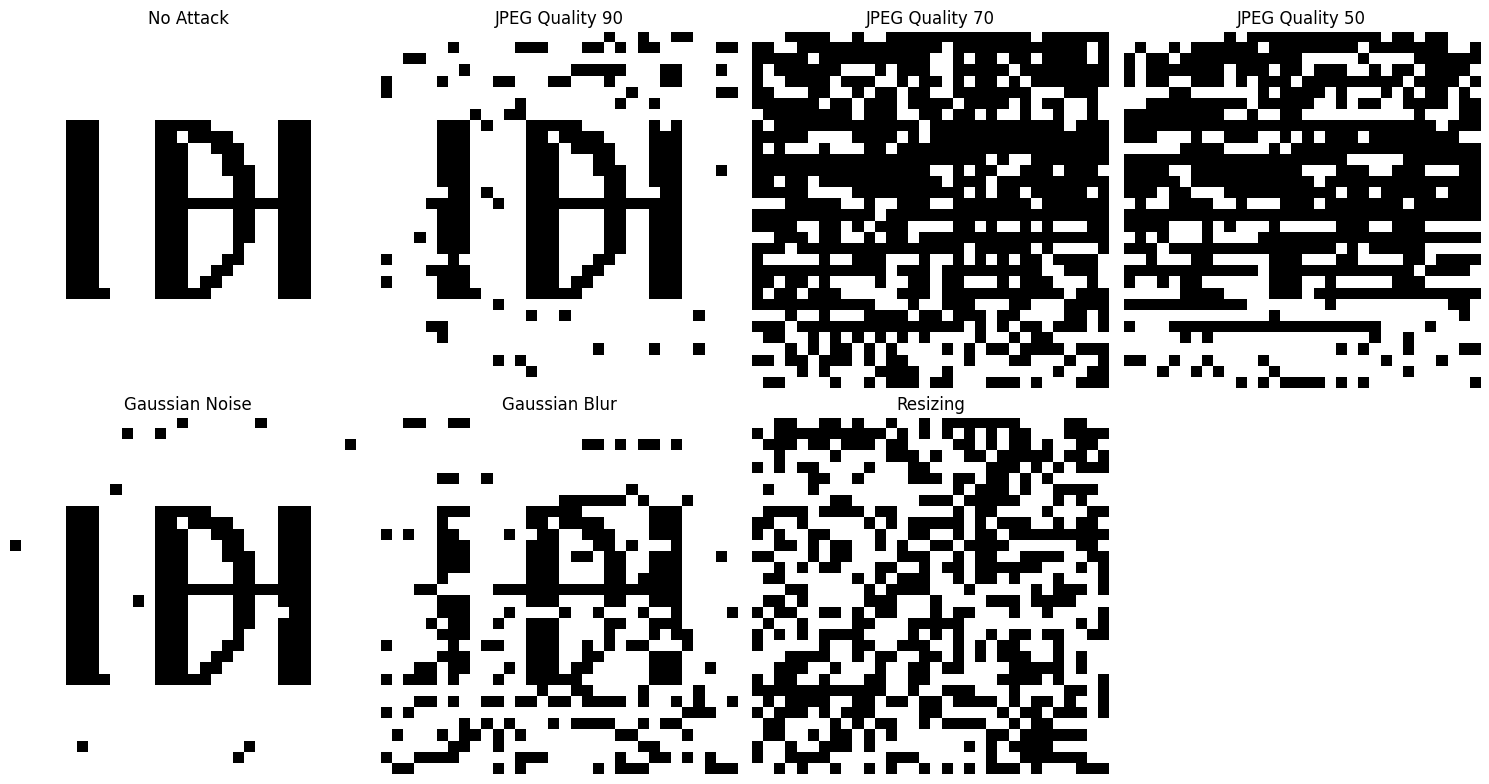

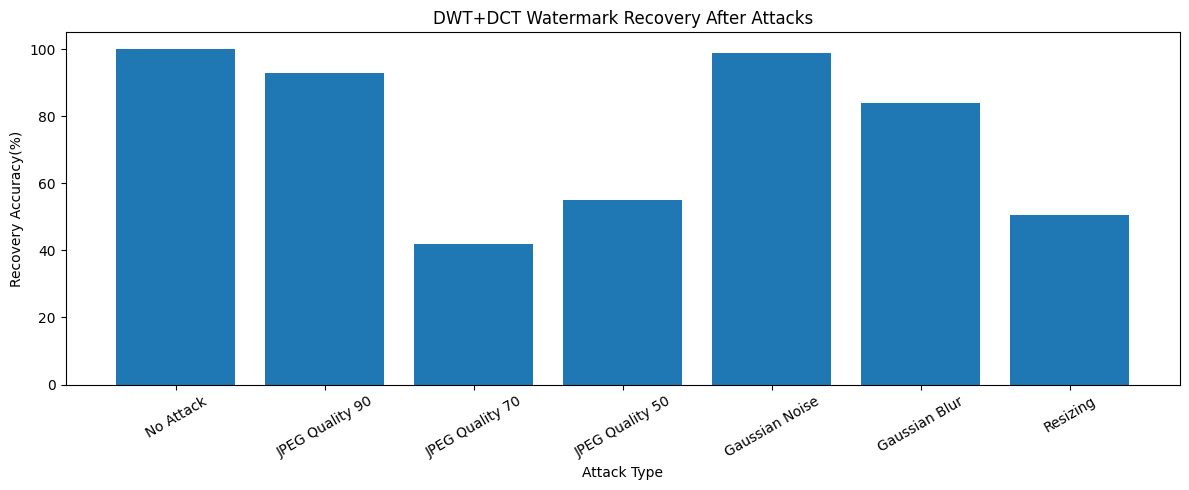

In [ ]:
# 1. JPEG Compression
def jpeg_attack(image,quality=70):
    _,encoded=cv2.imencode(".jpg",image,[cv2.IMWRITE_JPEG_QUALITY,quality])
    return cv2.imdecode(encoded,cv2.IMREAD_COLOR)


# 2. Gaussian Noise
def noise_attack(image):
    np.random.seed(42)
    noise=np.random.normal(0,5,image.shape)
    noisy=image.astype(np.float32)+noise
    return np.clip(noisy, 0, 255).astype(np.uint8)

# 3. Gaussian Blur
def blur_attack(image):
    return cv2.GaussianBlur(image,(3,3),0)

# 4. Resizing
def resize_attack(image):
    height,width=image.shape[:2]
    small=cv2.resize(image,(width//2,height//2))
    restored=cv2.resize(small,(width,height))
    return restored

attacks={
    "No Attack":saved_watermarked,
    "JPEG Quality 90":jpeg_attack(saved_watermarked, 90),
    "JPEG Quality 70":jpeg_attack(saved_watermarked, 70),
    "JPEG Quality 50":jpeg_attack(saved_watermarked, 50),
    "Gaussian Noise":noise_attack(saved_watermarked),
    "Gaussian Blur":blur_attack(saved_watermarked),
    "Resizing":resize_attack(saved_watermarked)
}

results=[]

for attack_name,attacked_image in attacks.items():

    # Extract watermark from attacked image
    recovered=extract_watermark(attacked_image,watermark.shape)

    # Calculate recovery metrics
    ber,accuracy,nc,wrong,total=calculate_recovery_metrics(watermark,recovered)

    results.append([attack_name, ber, accuracy, nc])

    print("\nAttack:",attack_name)
    print("BER:",round(ber, 4))
    print("Recovery Accuracy:",round(accuracy,2),"%")
    print("NC:",round(nc, 4))


df=pd.DataFrame(results,columns=["Attack","BER","Accuracy(%)","NC"])
print("\nATTACK COMPARISON")
display(df.round(4))

plt.figure(figsize=(15, 8))

for i,(attack_name,attacked_image) in enumerate(attacks.items()):

    recovered=extract_watermark(attacked_image,watermark.shape)

    plt.subplot(2,4,i+1)
    plt.imshow(recovered,cmap="gray",vmin=0,vmax=1)
    plt.title(attack_name)
    plt.axis("off")

plt.tight_layout()
plt.show()

plt.figure(figsize=(12,5))
plt.bar(df["Attack"],df["Accuracy(%)"])

plt.ylabel("Recovery Accuracy(%)")
plt.xlabel("Attack Type")
plt.title("DWT+DCT Watermark Recovery After Attacks")

plt.ylim(0,105)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


Running comprehensive attack benchmarking...


/usr/local/lib/python3.13/dist-packages/skimage/metrics/simple_metrics.py:168: RuntimeWarning: divide by zero encountered in scalar divide
  return 10 * np.log10((data_range**2) / err)



=== COMPREHENSIVE ATTACK EVALUATION TABLE ===


,Attack Category,Host PSNR (dB),Host SSIM,BER,Accuracy (%),NC,Incorrect Bits,Total Bits
0,No Attack,inf,1.0000,0.0000,100.0000,1.0000,0,1024
1,JPEG Q100,45.3515,0.9966,0.0000,100.0000,1.0000,0,1024
2,JPEG Q90,40.5872,0.9917,0.0723,92.7734,0.9549,74,1024
3,JPEG Q70,37.6664,0.9854,0.5811,41.8945,0.5445,595,1024
4,JPEG Q50,27.7701,0.9162,0.4502,54.9805,0.6726,461,1024
5,JPEG Q30,26.6028,0.8826,0.6406,35.9375,0.4723,656,1024
6,JPEG Q10,23.2259,0.7535,0.6582,34.1797,0.4479,674,1024
7,Gaussian Noise (σ=2),41.9918,0.9809,0.0000,100.0000,1.0000,0,1024
8,Gaussian Noise (σ=5),34.3566,0.9036,0.0117,98.8281,0.9928,12,1024
9,Gaussian Noise (σ=10),28.4582,0.7609,0.1201,87.9883,0.9242,123,1024



Table data saved to: watermark_output/watermark_attack_metrics.csv


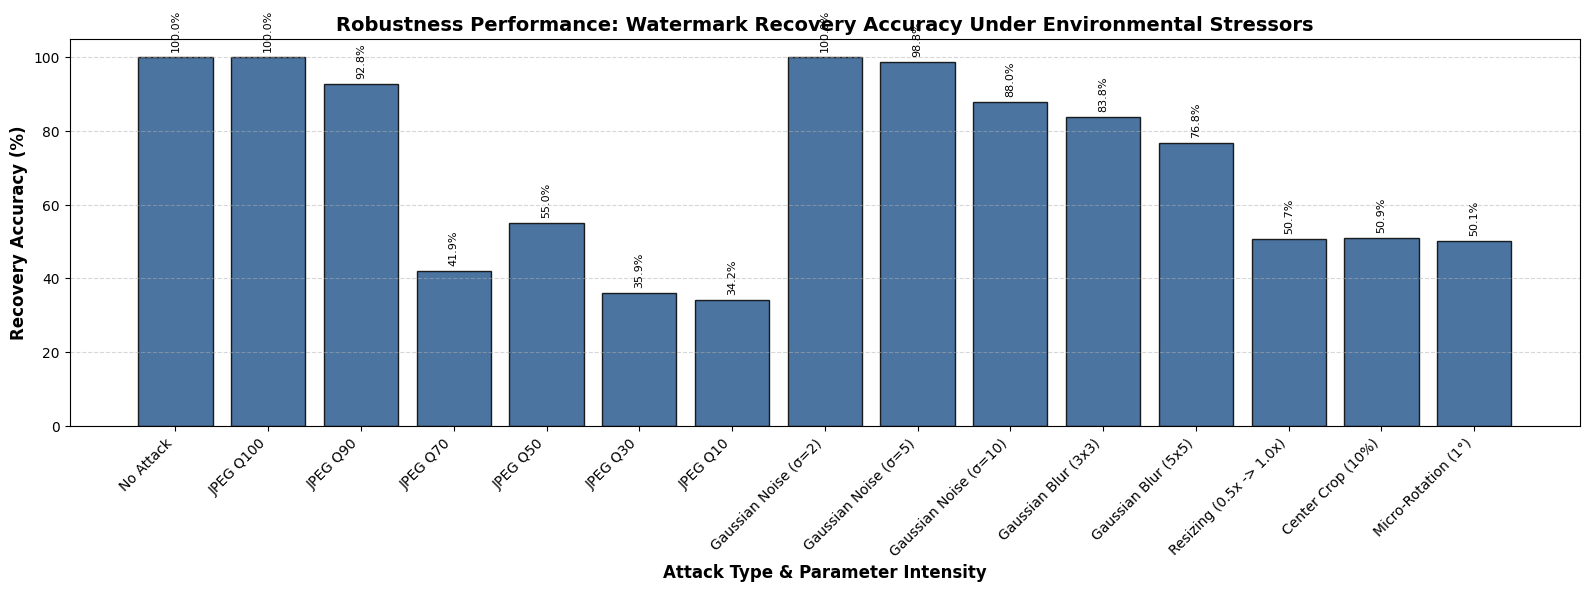

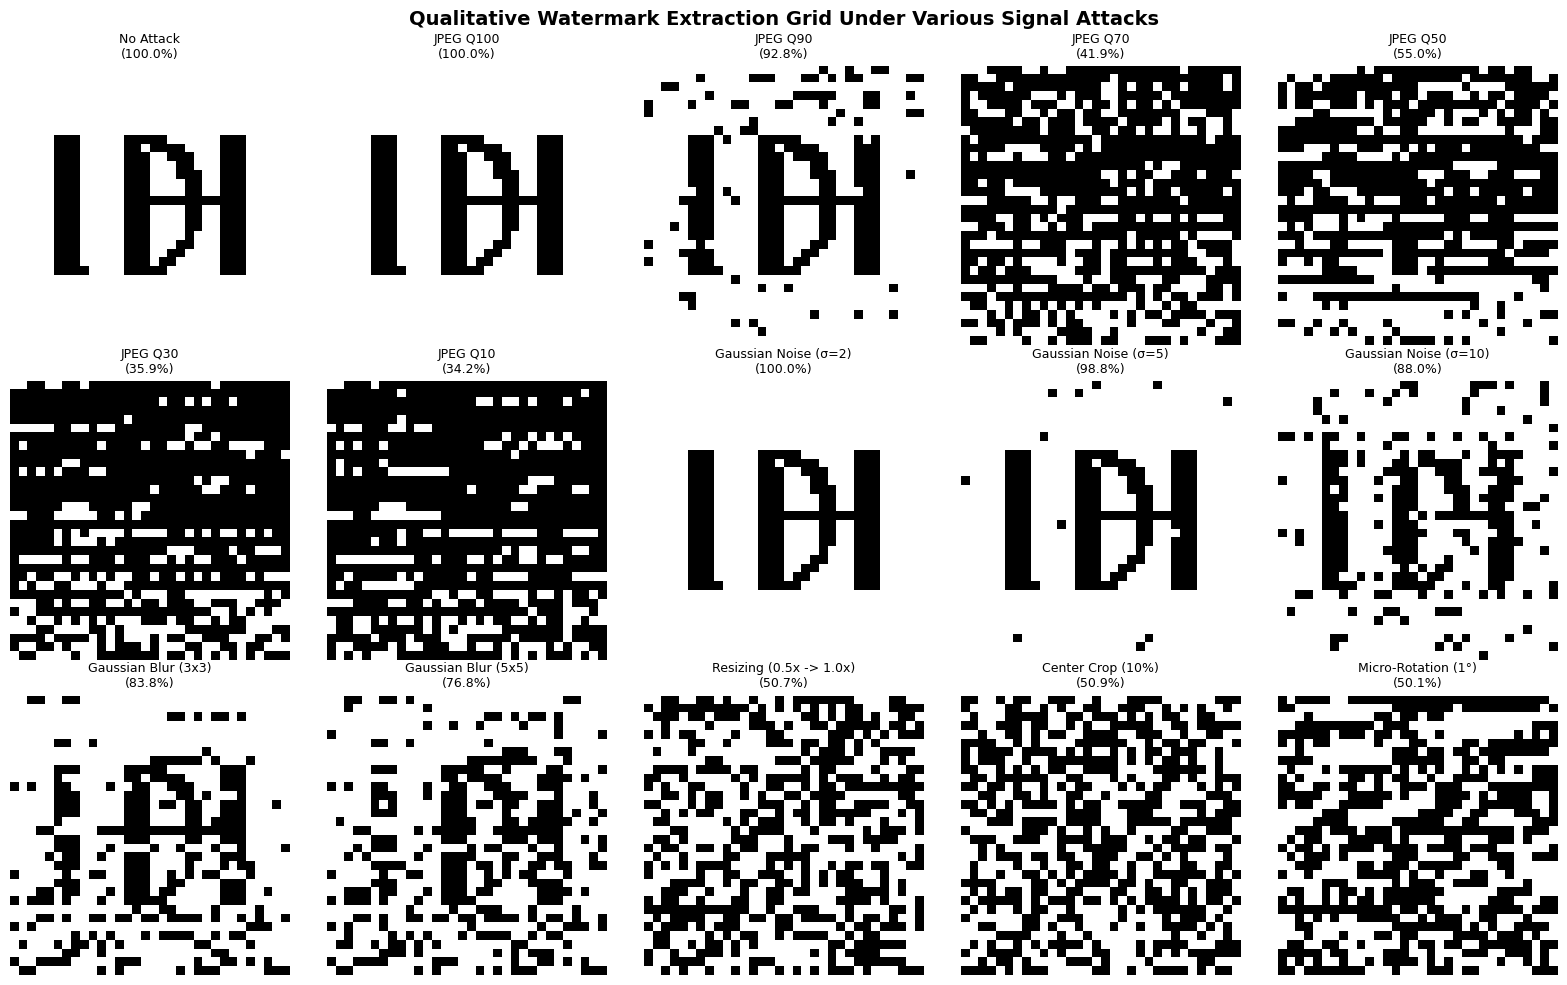

In [ ]:
# Fallback check for saved watermarked image
if 'saved_watermarked' not in globals():
    watermarked_path = os.path.join("watermark_output", "watermarked.png")
    if os.path.exists(watermarked_path):
        saved_watermarked = cv2.imread(watermarked_path, cv2.IMREAD_COLOR)
        print(f"Loaded 'saved_watermarked' from {watermarked_path}")
    else:
        raise NameError("The variable 'saved_watermarked' is not defined. Please run the previous embedding cell first.")

if 'watermark' not in globals():
    if 'logo_gray' in globals():
        watermark = read_binary_watermark(logo_gray, (32, 32))
    else:
        raise NameError("The variable 'watermark' is not defined. Please run the previous embedding cell first.")

def jpeg_attack(image, quality=70):
    _, encoded = cv2.imencode(".jpg", image, [cv2.IMWRITE_JPEG_QUALITY, quality])
    return cv2.imdecode(encoded, cv2.IMREAD_COLOR)

def noise_attack(image, std_dev=5.0):
    np.random.seed(42)
    noise = np.random.normal(0, std_dev, image.shape)
    noisy = image.astype(np.float32) + noise
    return np.clip(noisy, 0, 255).astype(np.uint8)

def blur_attack(image, kernel_size=(3,3)):
    return cv2.GaussianBlur(image, kernel_size, 0)

def resize_attack(image, scale=0.5):
    height, width = image.shape[:2]
    small = cv2.resize(image, (int(width * scale), int(height * scale)), interpolation=cv2.INTER_LINEAR)
    restored = cv2.resize(small, (width, height), interpolation=cv2.INTER_LINEAR)
    return restored

def crop_attack(image, crop_fraction=0.1):
    h, w = image.shape[:2]
    ch, cw = int(h * crop_fraction), int(w * crop_fraction)
    cropped = image[ch:h-ch, cw:w-cw]
    return cv2.resize(cropped, (w, h), interpolation=cv2.INTER_LINEAR)

def rotation_attack(image, angle=1.0):
    h, w = image.shape[:2]
    center = (w // 2, h // 2)
    matrix = cv2.getRotationMatrix2D(center, angle, 1.0)
    return cv2.warpAffine(image, matrix, (w, h), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REPLICATE)

attacks = {
    "No Attack": saved_watermarked,
    "JPEG Q100": jpeg_attack(saved_watermarked, 100),
    "JPEG Q90": jpeg_attack(saved_watermarked, 90),
    "JPEG Q70": jpeg_attack(saved_watermarked, 70),
    "JPEG Q50": jpeg_attack(saved_watermarked, 50),
    "JPEG Q30": jpeg_attack(saved_watermarked, 30),
    "JPEG Q10": jpeg_attack(saved_watermarked, 10),
    "Gaussian Noise (σ=2)": noise_attack(saved_watermarked, 2.0),
    "Gaussian Noise (σ=5)": noise_attack(saved_watermarked, 5.0),
    "Gaussian Noise (σ=10)": noise_attack(saved_watermarked, 10.0),
    "Gaussian Blur (3x3)": blur_attack(saved_watermarked, (3,3)),
    "Gaussian Blur (5x5)": blur_attack(saved_watermarked, (5,5)),
    "Resizing (0.5x -> 1.0x)": resize_attack(saved_watermarked, 0.5),
    "Center Crop (10%)": crop_attack(saved_watermarked, 0.1),
    "Micro-Rotation (1°)": rotation_attack(saved_watermarked, 1.0)
}

results = []

print("Running comprehensive attack benchmarking...")
for attack_name, attacked_image in attacks.items():
    host_psnr, host_ssim = calculate_image_quality(saved_watermarked, attacked_image)

    recovered = extract_watermark(attacked_image, watermark.shape)
    ber, accuracy, nc, wrong, total = calculate_recovery_metrics(watermark, recovered)

    results.append({
        "Attack Category": attack_name,
        "Host PSNR (dB)": host_psnr,
        "Host SSIM": host_ssim,
        "BER": ber,
        "Accuracy (%)": accuracy,
        "NC": nc,
        "Incorrect Bits": wrong,
        "Total Bits": total
    })

df = pd.DataFrame(results)
print("\n=== COMPREHENSIVE ATTACK EVALUATION TABLE ===")
display(df.round(4))

csv_path = os.path.join("watermark_output", "watermark_attack_metrics.csv")
df.to_csv(csv_path, index=False)
print(f"\nTable data saved to: {csv_path}")

plt.figure(figsize=(16, 6))
bars = plt.bar(df["Attack Category"], df["Accuracy (%)"], color='#2b5c8f', edgecolor='black', alpha=0.85)
plt.ylabel("Recovery Accuracy (%)", fontsize=12, fontweight='bold')
plt.xlabel("Attack Type & Parameter Intensity", fontsize=12, fontweight='bold')
plt.title("Robustness Performance: Watermark Recovery Accuracy Under Environmental Stressors", fontsize=14, fontweight='bold')
plt.ylim(0, 105)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.5)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 1.5, f"{yval:.1f}%", ha='center', va='bottom', fontsize=8, rotation=90)

plt.tight_layout()
chart_path = os.path.join("watermark_output", "robustness_accuracy_bar_chart.png")
plt.savefig(chart_path, dpi=300)
plt.show()

plt.figure(figsize=(16, 10))
for i, (attack_name, attacked_image) in enumerate(attacks.items()):
    recovered = extract_watermark(attacked_image, watermark.shape)
    plt.subplot(3, 5, i + 1)
    plt.imshow(recovered, cmap="gray", vmin=0, vmax=1)
    acc_val = df.loc[df["Attack Category"] == attack_name, "Accuracy (%)"].values[0]
    plt.title(f"{attack_name}\n({acc_val:.1f}%)", fontsize=9)
    plt.axis("off")

plt.suptitle("Qualitative Watermark Extraction Grid Under Various Signal Attacks", fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
grid_path = os.path.join("watermark_output", "qualitative_extraction_grid.png")
plt.savefig(grid_path, dpi=300)
plt.show()